## 0 - Importar librerias

In [2]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path

HERE = Path(sys.prefix).parent   # .venv -> agropredict-colombia
DATOS_RAW = HERE / "data" / "raw"
DATOS_PROCESADOS = HERE / "data" / "processed"
ARCHIVO = "20260526_BaseAgricola20192025.xlsx"
HOJA = "BasePagina"
DATASET= DATOS_RAW / ARCHIVO

## 1 — Cargar el archivo

El Excel de la UPRA no empieza con los datos en la primera fila. Los nombres de las columnas están **en la fila 9** del Excel. [`skiprows=8`.]

In [18]:
df = pd.read_excel(
    DATASET, sheet_name=HOJA, skiprows=8,
    dtype={"Código Dane departamento": str, "Código Dane municipio": str}
)
print(df.loc[0])
print(f"La base completa tiene {df.shape[0]:,} filas y {df.shape[1]} columnas.")
print("\nColumnas disponibles:")
for col in df.columns:
    print(" -", col)

Código Dane departamento                          05
Departamento                               Antioquia
Código Dane municipio                          05001
Municipio                                   Medellín
Desagregación cultivo                           Apio
Cultivo                                         Apio
Ciclo del cultivo                        Transitorio
Grupo cultivo                             Hortalizas
Subgrupo                         Hortalizas de tallo
Año                                             2021
Periodo                                        2021A
Área sembrada (ha)                               8.0
Área cosechada (ha)                              8.0
Producción (t)                                 128.0
Rendimiento (t/ha)                              16.0
Nombre científico del cultivo       Apium graveolens
Código del cultivo                           1050600
Estado físico del cultivo                  En fresco
Name: 0, dtype: object
La base completa tiene 

## 2 — Filtrar cultivo maíz

La base trae cientos de cultivos. Nuestro proyecto es **solo maíz**.

In [19]:
es_maiz = df["Cultivo"].astype(str).str.upper().str.contains("MAIZ|MAÍZ", regex=True, na=False)
maiz = df[es_maiz].copy()

print(f"Registros de maíz: {len(maiz):,}")
print(f"Municipios distintos: {maiz['Código Dane municipio'].nunique():,}")
print(f"Departamentos distintos: {maiz['Código Dane departamento'].nunique()}")
print(f"Años cubiertos: {sorted(maiz['Año'].dropna().unique().tolist())}")

Registros de maíz: 21,992
Municipios distintos: 1,050
Departamentos distintos: 32
Años cubiertos: [2019, 2020, 2021, 2022, 2023, 2024, 2025]


El maíz viene en **6 variantes** y no todas rinden igual:
el maíz *tecnificado* usa mejor tecnología y produce más que el *tradicional*.

In [20]:
maiz["Desagregación cultivo"].value_counts()

Desagregación cultivo
Maíz amarillo tradicional    9247
Maíz blanco tradicional      4928
Maíz tradicional             3464
Maíz amarillo tecnificado    2098
Maíz blanco tecnificado      1432
Maíz tecnificado              823
Name: count, dtype: int64

De la exploración de los datos se evidenció que hay registros donde el **área cosechada es mayor que la sembrada**.
En teoría no se puede cosechar más de lo que se sembró. La UPRA documenta que esto aparece
por un cambio en su metodología a partir de 2022.

In [21]:
cosechada_mayor = maiz["Área cosechada (ha)"] > maiz["Área sembrada (ha)"]
print(f"Registros con área cosechada > sembrada: {cosechada_mayor.sum():,} "
f"({cosechada_mayor.mean()*100:.1f}% del total)")
print("\nDistribución por año:")
print(maiz.loc[cosechada_mayor, "Año"].value_counts().sort_index())

Registros con área cosechada > sembrada: 4,257 (19.4% del total)

Distribución por año:
Año
2022    1056
2023    1067
2024    1051
2025    1083
Name: count, dtype: int64


## 3 — Limpiar y etiquetar

**a) Se elimina** (no sirve para entrenar el modelo):
- Registros con rendimiento en cero: si no hubo cosecha, no hay nada que predecir.

**b) Se etiqueta** (1 = sí, 0 = no):
- Casos “cosechada > sembrada”.
- Casos donde el rendimiento puede ser atípico.


In [22]:
# a) Eliminar rendimientos en cero
antes = len(maiz)
maiz = maiz[maiz["Rendimiento (t/ha)"] > 0].copy()
print(f"Eliminados por rendimiento en cero: {antes - len(maiz):,}")
print(f"Quedan: {len(maiz):,} registros")

Eliminados por rendimiento en cero: 1,381
Quedan: 20,611 registros


In [23]:
rend = maiz["Rendimiento (t/ha)"]

print("Rendimiento del maíz (t/ha):")
print(f"  Percentil 95: {rend.quantile(0.95):.1f}")
print(f"  Percentil 99: {rend.quantile(0.99):.1f}")
print(f"  Máximo:       {rend.max():.1f}")
print(f"  Registros > 12 t/ha: {(rend > 12).sum()} ({(rend > 12).mean()*100:.2f}%)")

Rendimiento del maíz (t/ha):
  Percentil 95: 6.0
  Percentil 99: 8.0
  Máximo:       28.0
  Registros > 12 t/ha: 41 (0.20%)


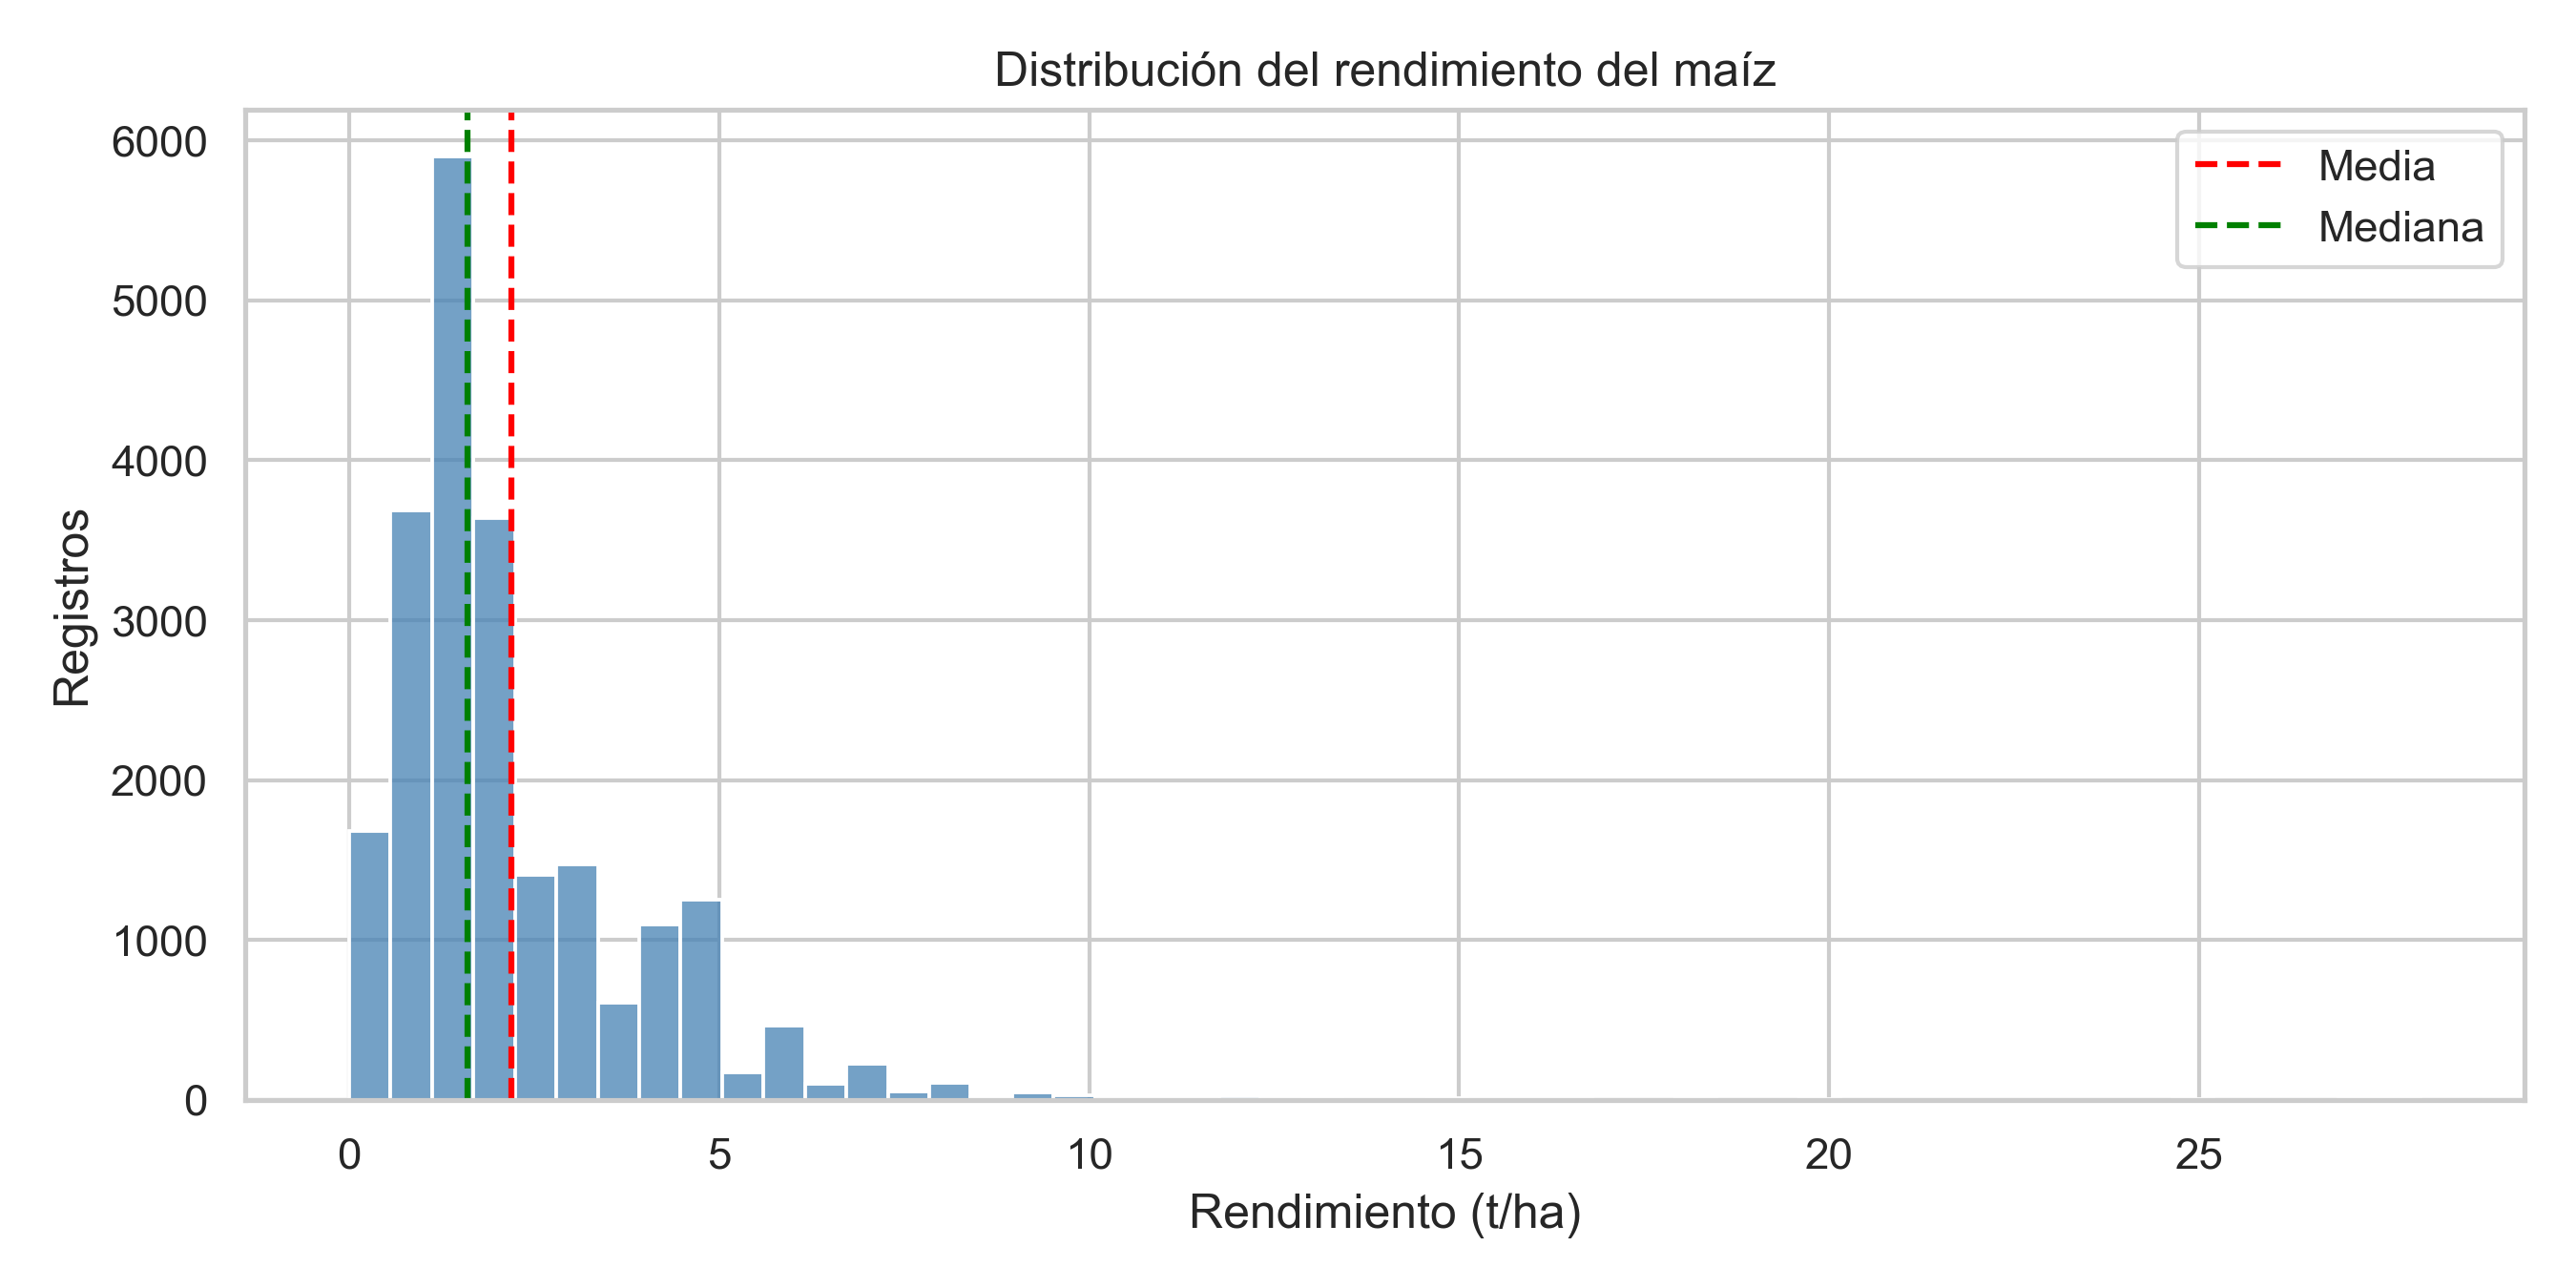

El 99 % de los registros de maíz rinde 8 t/ha o menos. Un valor sobre 12 t/ha es agronómicamente improbable en Colombia, así que lo marcamos como posible error.

In [24]:
# b) Marcar los casos dudosos

# Bandera 1: área cosechada mayor que la sembrada
maiz["flag_cosechada_mayor_sembrada"] = (
    maiz["Área cosechada (ha)"] > maiz["Área sembrada (ha)"]
).astype(int)

# Bandera 2: rendimientos extremadamente altos (posibles valores atípicos).
#   Usamos un umbral alto y razonable para maíz; el equipo puede ajustarlo luego.
maiz["flag_rendimiento_atipico"] = (maiz["Rendimiento (t/ha)"] > 12).astype(int)

print("Casos marcados:")
print("  cosechada > sembrada:", int(maiz['flag_cosechada_mayor_sembrada'].sum()))
print("  rendimiento atípico (>12 t/ha):", int(maiz['flag_rendimiento_atipico'].sum()))

Casos marcados:
  cosechada > sembrada: 4257
  rendimiento atípico (>12 t/ha): 41


## 4— Crear columnas nuevas útiles para el modelo

Con lo que ya tenemos, construimos tres columnas que ayudan a explicar el rendimiento:

- **sistema_productivo**: agrupa las 6 variantes en *tecnificado* o *tradicional*. Es la
  diferencia más grande que vimos en los rendimientos.
- **semestre**: saca la letra A o B del periodo (primer o segundo semestre del año).
- **post_cambio_metodologico**: indica si el registro es de 2022 en adelante, cuando cambió
  la metodología de la UPRA.

In [25]:
# Sistema productivo: tecnificado vs tradicional
texto_desag = maiz["Desagregación cultivo"].astype(str).str.lower()
maiz["sistema_productivo"] = np.where(
    texto_desag.str.contains("tecnif"), "tecnificado",
    np.where(texto_desag.str.contains("tradic"), "tradicional", "otro")
)

# Semestre B (segundo semestre): 1 si el periodo termina en B, 0 si termina en A
maiz["semestre_b"] = (maiz["Periodo"].astype(str).str.endswith("B")).astype(int)

# posterior al cambio de metodología?
maiz["post_cambio_metodologico"] = (maiz["Año"] >= 2022).astype(int)

maiz[["Desagregación cultivo", "sistema_productivo",
      "Periodo", "semestre_b", "Año", "post_cambio_metodologico"]].head()

,Desagregación cultivo,sistema_productivo,Periodo,semestre_b,Año,post_cambio_metodologico
379,Maíz amarillo tradicional,tradicional,2021A,0,2021,0
380,Maíz amarillo tradicional,tradicional,2021B,1,2021,0
381,Maíz amarillo tradicional,tradicional,2022A,0,2022,1
382,Maíz amarillo tradicional,tradicional,2022B,1,2022,1
383,Maíz amarillo tradicional,tradicional,2023A,0,2023,1


Comprobación rápida: el rendimiento promedio debería ser mayor en el maíz tecnificado
que en el tradicional. Esto confirma que la columna nueva tiene sentido.

In [26]:
maiz.groupby("sistema_productivo")["Rendimiento (t/ha)"].mean().round(2)

sistema_productivo
tecnificado    4.34
tradicional    1.84
Name: Rendimiento (t/ha), dtype: float64

## 5 — Seleccionar columnas finales y guardar

Nos quedamos con las columnas que vamos a necesitar en el proyecto y les ponemos nombres sencillos (sin tildes ni paréntesis) para que sea más cómodo programar después. Cumplen dos roles:

- **Identificación y análisis:** códigos DANE y nombres de departamento y municipio. No son variables del modelo; sirven para identificar territorios, cruzar con otras fuentes y agrupar en el análisis.
- **Insumo del modelo:** sistema productivo, semestre, año, áreas y producción, junto con el rendimiento como variable objetivo.

La selección definitiva de qué variables entran al modelo se hará en la fase de modelado. Aquí solo dejamos la base limpia y completa.

In [28]:
columnas_finales = {
    "Código Dane departamento": "cod_departamento",
    "Departamento": "departamento",
    "Código Dane municipio": "cod_municipio",
    "Municipio": "municipio",
    "Desagregación cultivo": "desagregacion",
    "sistema_productivo": "sistema_productivo",
    "Año": "anio",
    "semestre_b": "semestre_b",
    "post_cambio_metodologico": "post_cambio_metodologico",
    "Área sembrada (ha)": "area_sembrada",
    "Área cosechada (ha)": "area_cosechada",
    "Producción (t)": "produccion",
    "Rendimiento (t/ha)": "rendimiento",
    "flag_cosechada_mayor_sembrada": "flag_cosechada_mayor_sembrada",
    "flag_rendimiento_atipico": "flag_rendimiento_atipico",
}

limpio = maiz[list(columnas_finales.keys())].rename(columns=columnas_finales)
print(f"Tabla final: {limpio.shape[0]:,} filas y {limpio.shape[1]} columnas")
limpio.head()

Tabla final: 20,611 filas y 15 columnas


,cod_departamento,departamento,cod_municipio,municipio,desagregacion,sistema_productivo,anio,semestre_b,post_cambio_metodologico,area_sembrada,area_cosechada,produccion,rendimiento,flag_cosechada_mayor_sembrada,flag_rendimiento_atipico
379,05,Antioquia,05002,Abejorral,Maíz amarillo tradicional,tradicional,2021,0,0,51.0,49.0,98.0,2.0,0,0
380,05,Antioquia,05002,Abejorral,Maíz amarillo tradicional,tradicional,2021,1,0,40.0,35.0,70.0,2.0,0,0
381,05,Antioquia,05002,Abejorral,Maíz amarillo tradicional,tradicional,2022,0,1,40.0,40.0,80.0,2.0,0,0
382,05,Antioquia,05002,Abejorral,Maíz amarillo tradicional,tradicional,2022,1,1,35.0,35.0,70.0,2.0,0,0
383,05,Antioquia,05002,Abejorral,Maíz amarillo tradicional,tradicional,2023,0,1,40.0,35.0,70.0,2.0,0,0


In [29]:
# Guardamos en dos formatos:
#  - CSV: fácil de abrir en Excel o compartir.
#  - Parquet: más liviano y rápido, ideal para los siguientes pasos en Python.

DATOS_PROCESADOS.mkdir(parents=True, exist_ok=True)   # crea la carpeta si no existe

limpio.to_parquet(DATOS_PROCESADOS / "maiz_preprocesado.parquet", index=False)
limpio.to_csv(DATOS_PROCESADOS / "maiz_preprocesado.csv", index=False, encoding="utf-8-sig")

print(f"Guardado en: {DATOS_PROCESADOS}")

Guardado en: /Users/Simon/Library/CloudStorage/OneDrive-SharedLibraries-ProductosAlimenticiosPascualS.A/Inteligencia Comercial - 5-Semestre/MIID-4304 Despliegue/Proyecto/agropredict-colombia/data/processed


## Resumen

Partimos de un Excel con todos los cultivos del país y terminamos con una tabla limpia,
solo de maíz, lista para la construcción de modelos.

**Lo que hicimos:**
- Cargamos el archivo saltando las notas del encabezado y leímos los códigos DANE como
  texto, para conservar el cero inicial (por ejemplo `05` y `05001`).
- Filtramos únicamente el maíz: 21.992 registros iniciales en 1.050 municipios de 32
  departamentos.
- Revisamos la calidad: sin vacíos ni negativos, pero con rendimientos en cero y casos de
  cosechada > sembrada asociados al cambio de metodología de la UPRA.
- Eliminamos los rendimientos en cero (quedaron 20.611 registros) y **etiquetamos**, sin
  borrar, los casos dudosos mediante banderas.
- Creamos columnas útiles: sistema productivo (tecnificado/tradicional), semestre
  (`semestre_b`, 0/1) y etiqueta de cambio metodológico.
- Guardamos el resultado limpio en CSV y Parquet, en la carpeta de datos procesados.
